In [1]:
import matplotlib.pyplot as plt
import math
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme(style="whitegrid")

from sklearn.feature_selection import f_classif
from sklearn.model_selection import train_test_split

from scipy.stats import chi2_contingency
from scipy.stats.contingency import association


PLOT_BLUE = "#1779A8"
PLOT_ORANGE = "#C96A00"
CLASS_COLOURS = (PLOT_BLUE, PLOT_ORANGE)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)  # For reproducibility
FIGSIZE = (10, 6)

raw_train = pd.read_csv('../data/raw/train.csv', index_col="ID")
raw_clientes = pd.read_csv('../data/raw/clientes.csv', index_col="customer_id")

raw = pd.merge(raw_train, raw_clientes, how='left', on='customer_id')


# <font color='#E8800A'>Missing values</font> <a class="anchor" id="missing"></a>

In [2]:
print(f"Total number of missing values: {raw.isna().sum().sum()}")

na_summary = pd.DataFrame({
    "NA_count": raw.isna().sum(),
    "NA_percentage": raw.isna().mean() * 100
})

print(na_summary.sort_values("NA_count", ascending=False))

Total number of missing values: 25302
                                NA_count  NA_percentage
customer_type                       6534     100.000000
street                              3834      58.677686
island                              2211      33.838384
city                                2150      32.904806
prior_std_gap_days                  1478      22.620141
prior_mean_gap_days                 1308      20.018365
prior_std_purchase_value            1113      17.033976
prior_mean_purchase_value            862      13.192531
days_since_previous_purchase         861      13.177227
prior_min_purchase_value             668      10.223447
prior_max_purchase_value             668      10.223447
postal_area                          278       4.254668
transport_method                     261       3.994490
spend_365d                           260       3.979186
payment_type                         260       3.979186
warehouse                            260       3.979186
salesperso

<Axes: title={'center': 'Missing Values by Feature'}, ylabel='Missing values (%)'>

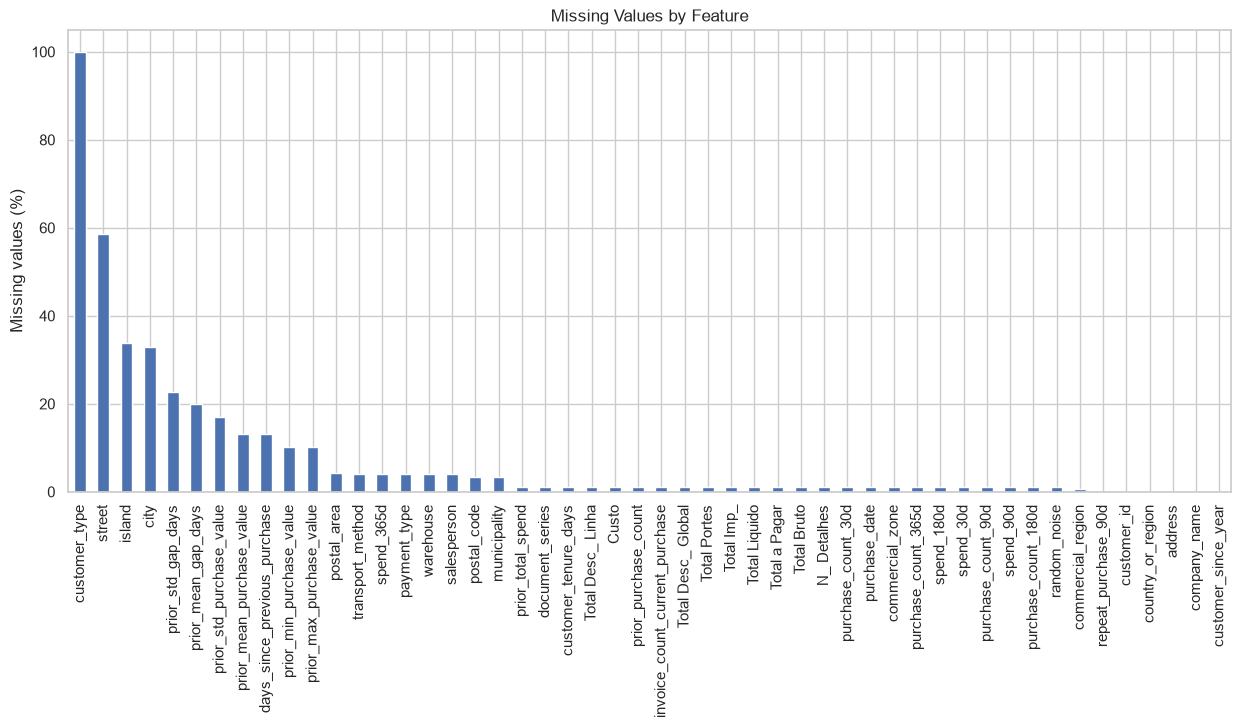

In [3]:
na_percentage = raw.isna().mean() * 100

na_percentage = na_percentage.sort_values(ascending=False)

na_percentage.plot(
    kind="bar",
    figsize=(15, 6),
    ylabel="Missing values (%)",
    title="Missing Values by Feature"
)

In [4]:
target = "repeat_purchase_90d"

rows = []

# Do not test the target itself as a predictor
features = [column for column in raw.columns if column != target]

for column in features:
    missing_flag = raw[column].isna()

    table = pd.crosstab(
        missing_flag,
        raw[target],
        dropna=False,
    )

    # Cramér's V and chi-square are undefined when there is
    # no variation in the missingness flag or target.
    if table.shape[0] < 2 or table.shape[1] < 2:
        rows.append({
            "feature": column,
            "missing_count": int(missing_flag.sum()),
            "missing_percentage": 100 * missing_flag.mean(),
            "chi2": np.nan,
            "p": np.nan,
            "Cramer's V": np.nan,
            "min expected count": np.nan,
        })
        continue

    chi2, p, _, expected = chi2_contingency(table)

    rows.append({
        "feature": column,
        "missing_count": int(missing_flag.sum()),
        "missing_percentage": 100 * missing_flag.mean(),
        "chi2": chi2,
        "p": p,
        "Cramer's V": association(
            table,
            method="cramer",
            correction=True,
        ),
        "min expected count": expected.min(),
    })

missing_target_table = (
    pd.DataFrame(rows)
    .sort_values(
        ["p", "Cramer's V"],
        ascending=[True, False],
        na_position="last",
    )
    .reset_index(drop=True)
)

missing_target_table

,feature,missing_count,missing_percentage,chi2,p,Cramer's V,min expected count
0,prior_std_gap_days,1478,22.620141,278.185717,1.866227e-62,0.206337,651.460055
1,prior_std_purchase_value,1113,17.033976,216.371720,5.595427e-49,0.181975,490.578512
2,prior_mean_gap_days,1308,20.018365,159.759801,1.276818e-36,0.156367,576.528926
3,prior_min_purchase_value,668,10.223447,130.825344,2.703792e-30,0.141500,294.435262
4,prior_max_purchase_value,668,10.223447,130.825344,2.703792e-30,0.141500,294.435262
5,days_since_previous_purchase,861,13.177227,101.853360,5.978776e-24,0.124853,379.504132
6,prior_mean_purchase_value,862,13.192531,98.159689,3.859676e-23,0.122568,379.944904
7,island,2211,33.838384,87.915239,6.832027e-21,0.115996,974.545455
8,street,3834,58.677686,28.999160,7.240971e-08,0.066620,1190.082645
9,municipality,217,3.321090,27.707515,1.411135e-07,0.065119,95.647383


In [5]:
non_negative = [
    column for column in numeric
    if column != "random_noise"
]

for column in non_negative:
    print(
        f"{column:32s} "
        f"min {raw[column].min():10.2f} "
        f"negative rows {(raw[column] < 0).sum():5d}"
    )

rows_with_null_before = raw.isna().any(axis=1)

step3 = raw.copy()
step3[non_negative] = step3[non_negative].mask(
    step3[non_negative] < 0
)

rows_with_null_after = step3.isna().any(axis=1)

print(
    f"\nrows with a null: {rows_with_null_before.sum():,} -> "
    f"{rows_with_null_after.sum():,} "
    f"({100 * rows_with_null_after.mean():.2f}% of {len(step3):,})"
)

print(
    f"null cells:       {raw.isna().sum().sum():,} -> "
    f"{step3.isna().sum().sum():,}"
)

NameError: name 'numeric' is not defined